In [24]:
from scipy import optimize
import numpy as np
import matplotlib.pyplot as plt

In [25]:
def h1(x1, x2):
    return x1**2 + x2**2


def h2(x1, x2):
    return x1**2


def h3(x1, x2):
    return np.exp(x1)


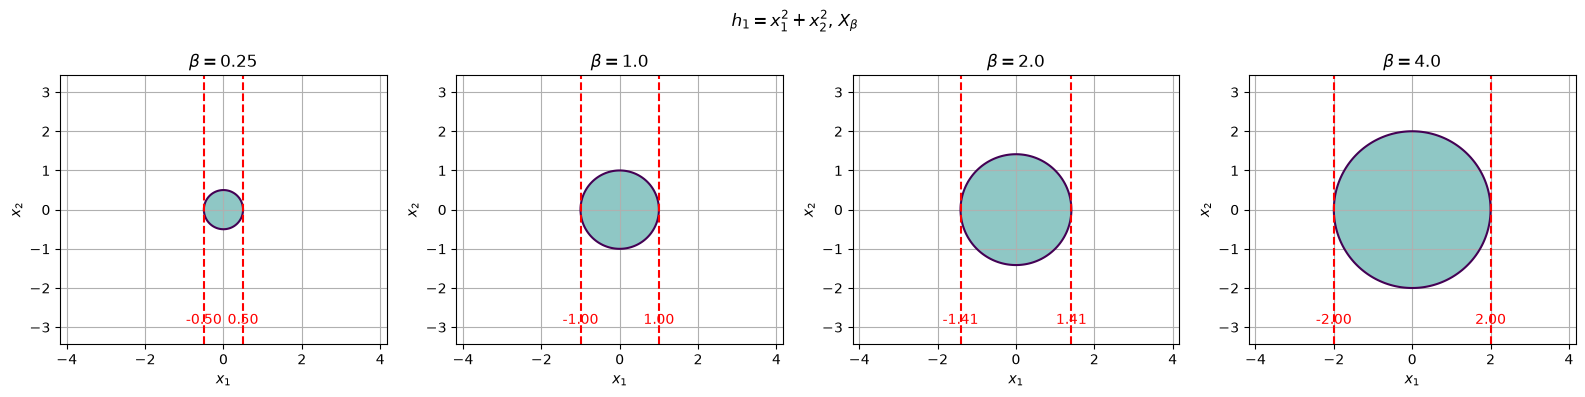

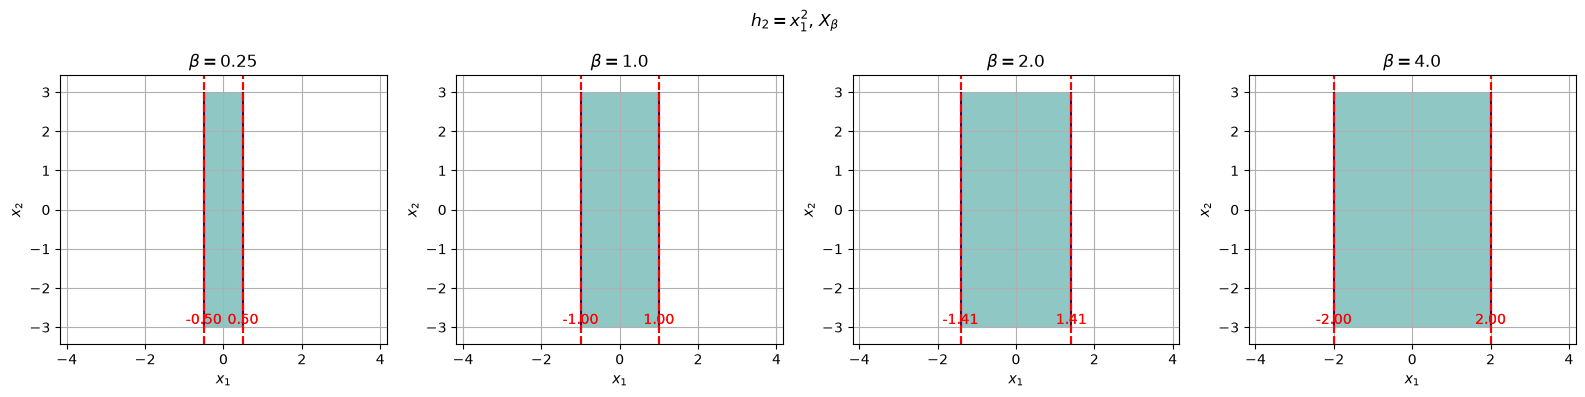

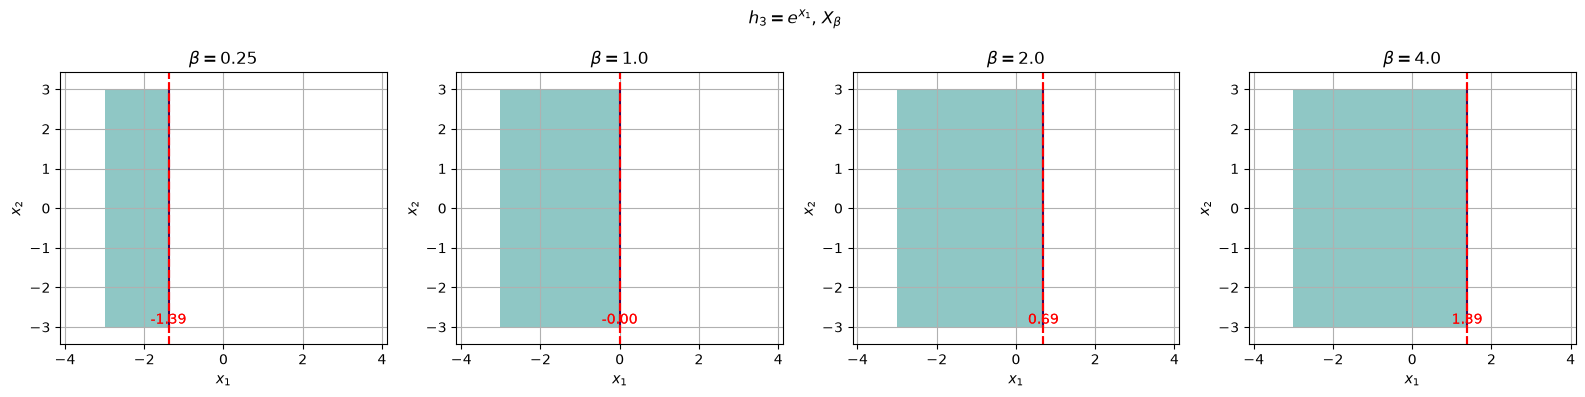

In [47]:
from scipy.spatial.distance import pdist

X2, X1 = np.mgrid[-3:3:400j, -3:3:400j]
betas = [0.25, 1.0, 2.0, 4.0]
functions = [(h1, "$h_1=x_1^2+x_2^2$"), (h2, "$h_2=x_1^2$"), (h3, "$h_3=e^{x_1}$")]
diams = {}

for h, title in functions:
    fig, axes = plt.subplots(1, len(betas), figsize=(16, 4))

    Z = h(X1, X2)

    for ax, beta in zip(axes, betas):
        ax.contourf(X1, X2, Z, levels=[Z.min(), beta], alpha=0.5)

        cs = ax.contour(X1, X2, Z, levels=[beta])

        for path in cs.allsegs[0]:
            diameter = np.max(pdist(path))
            diams[(h, beta)] = diameter

            x1_boundary = path[:, 0]
            x2_boundary = path[:, 1]

            x1_min = x1_boundary.min()
            x1_max = x1_boundary.max()
            
            for x_line in [x1_min, x1_max]:
                ax.axvline(
                    x_line,
                    color='red',
                    linestyle='--'
                )

                ax.text(
                    x_line,
                    ax.get_ylim()[0],
                    f"{x_line:.2f}",
                    color="red",
                    ha="center",
                    va="bottom"
                )

        ax.set_title(f"$\\beta={beta}$")

        ax.set_xlabel("$x_1$")
        ax.set_ylabel("$x_2$")

        ax.axis("equal")
        ax.grid()

    fig.suptitle(title + ", $X_\\beta$")
    plt.tight_layout()
    plt.show()

In [48]:
theta = 1.0
for beta in betas:
    diameter_h1 = diams[(h1, beta)]
    if diameter_h1 <= 2.0 * np.sqrt(beta / theta):
        print(f"Condition satisfied for beta={beta}: diameter={diameter_h1:.4f}")
    else:
        print(f"Condition NOT satisfied for beta={beta}: diameter={diameter_h1:.4f}")

Condition satisfied for beta=0.25: diameter=1.0000
Condition satisfied for beta=1.0: diameter=2.0000
Condition satisfied for beta=2.0: diameter=2.8284
Condition satisfied for beta=4.0: diameter=4.0000


In [52]:
min_h1 = optimize.minimize(lambda x: h1(x[0], x[1]), [2, 3])
print(f"Minimum of h1: {min_h1.fun:.6f}")
print(f"Point: {min_h1.x[0]:.6f}, {min_h1.x[1]:.6f}")

Minimum of h1: 0.000000
Point: 0.000000, -0.000000
